In [1]:
import pandas as pd
from neo4j import GraphDatabase
from pathlib import Path
from getpass import getpass

In [2]:
project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

folder = project_folder / "data" / "outputs"

roads_df = pd.read_csv(folder / "roads.csv", dtype={"id": str})
junctions_df = pd.read_csv(folder / "junctions.csv", dtype={"id": str})
incidents_df = pd.read_csv(folder / "incidents.csv")
congestion_df = pd.read_csv(folder / "congestion.csv")

print("SOURCE DATA COUNTS")
print("------------------")

print("Roads:", len(roads_df))
print("Junctions:", len(junctions_df))
print("Incidents:", len(incidents_df))
print("Congestion events:", len(congestion_df))

SOURCE DATA COUNTS
------------------
Roads: 794
Junctions: 276
Incidents: 3
Congestion events: 75


In [3]:
uri = "bolt://localhost:7687"
username = "neo4j"
password = getpass("Enter Neo4j password: ")

driver = GraphDatabase.driver(uri, auth=(username, password))

driver.verify_connectivity()

print("Connected to Neo4j!")

Connected to Neo4j!


In [4]:
queries = {
    "Roads": """
        MATCH (r:Road)
        WHERE r.id STARTS WITH 'SUMO_'
        RETURN count(r) AS total
    """,

    "Junctions": """
        MATCH (j:Junction)
        WHERE j.id STARTS WITH 'SUMO_'
        RETURN count(j) AS total
    """,

    "Incidents": """
        MATCH (i:Incident)
        WHERE i.source = 'Simulated'
        RETURN count(i) AS total
    """,

    "Congestion": """
        MATCH (c:Congestion)
        WHERE c.source = 'SUMO_Simulation'
        RETURN count(c) AS total
    """
}

graph_counts = {}

with driver.session(database="neo4j") as session:
    for name, query in queries.items():
        graph_counts[name] = session.run(query).single()["total"]

print("NEO4J GRAPH COUNTS")
print("------------------")

for name, count in graph_counts.items():
    print(name, ":", count)

NEO4J GRAPH COUNTS
------------------
Roads : 794
Junctions : 276
Incidents : 3
Congestion : 75


In [5]:
source_counts = {
    "Roads": len(roads_df),
    "Junctions": len(junctions_df),
    "Incidents": len(incidents_df),
    "Congestion": len(congestion_df)
}

results = []

for name in source_counts:

    source = source_counts[name]
    imported = graph_counts[name]

    completeness = (imported / source * 100) if source > 0 else None

    results.append({
        "Entity": name,
        "Source Count": source,
        "Neo4j Count": imported,
        "Completeness (%)": completeness
    })

completeness_df = pd.DataFrame(results)

completeness_df

,Entity,Source Count,Neo4j Count,Completeness (%)
0,Roads,794,794,100.0
1,Junctions,276,276,100.0
2,Incidents,3,3,100.0
3,Congestion,75,75,100.0


In [6]:
query = """
MATCH (r:Road)
WHERE r.id STARTS WITH 'SUMO_'
  AND (
      r.length IS NULL OR
      r.speedLimit IS NULL OR
      r.lanes IS NULL
  )
RETURN count(r) AS missing
"""

with driver.session(database="neo4j") as session:
    missing = session.run(query).single()["missing"]

print("Road nodes missing important properties:", missing)

Road nodes missing important properties: 0


In [7]:
query = """
MATCH (r:Road)
WHERE r.id STARTS WITH 'SUMO_'
  AND NOT (r)-[:CONNECTED_TO]->(:Junction)
RETURN count(r) AS orphans
"""

with driver.session(database="neo4j") as session:
    orphans = session.run(query).single()["orphans"]

print("Roads without junction relationships:", orphans)

Roads without junction relationships: 0


In [8]:
query = """
MATCH (i:Incident)
WHERE i.source = 'Simulated'
  AND NOT (i)-[:LOCATED_AT]->(:Road)
RETURN count(i) AS missing
"""

with driver.session(database="neo4j") as session:
    incident_missing = session.run(query).single()["missing"]

query = """
MATCH (c:Congestion)
WHERE c.source = 'SUMO_Simulation'
  AND NOT (c)-[:LOCATED_AT]->(:Road)
RETURN count(c) AS missing
"""

with driver.session(database="neo4j") as session:
    congestion_missing = session.run(query).single()["missing"]

print("Incidents without roads:", incident_missing)
print("Congestion events without roads:", congestion_missing)

Incidents without roads: 0
Congestion events without roads: 0


In [9]:
output = folder / "graph_completeness.csv"

completeness_df.to_csv(output, index=False)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [10]:
import time

In [11]:
performance_queries = {
    "All Roads": """
        MATCH (r:Road)
        WHERE r.id STARTS WITH 'SUMO_'
        RETURN count(r) AS total
    """,

    "Blocked Roads": """
        MATCH (r:Road)
        WHERE r.id STARTS WITH 'SUMO_'
          AND r.status = 'Blocked'
        RETURN count(r) AS total
    """,

    "High Speed Roads": """
        MATCH (r:Road)
        WHERE r.speedLimit > 50
        RETURN count(r) AS total
    """,

    "Simulated Incidents": """
        MATCH (i:Incident)
        WHERE i.source = 'Simulated'
        RETURN count(i) AS total
    """,

    "Congested Roads": """
        MATCH (c:Congestion)-[:LOCATED_AT]->(r:Road)
        WHERE c.source = 'SUMO_Simulation'
        RETURN count(c) AS total
    """,

    "Incident Connections": """
        MATCH (i:Incident)-[:BLOCKS]->(r:Road)
        MATCH (r)-[:CONNECTED_TO]->(j:Junction)
        WHERE i.source = 'Simulated'
        RETURN count(DISTINCT j) AS total
    """
}

print("Total performance queries:", len(performance_queries))

Total performance queries: 6


In [12]:
results = []

with driver.session(database="neo4j") as session:

    for name, query in performance_queries.items():

        times = []

        for i in range(6):

            start = time.perf_counter()

            result = session.run(query)
            result.consume()

            end = time.perf_counter()

            if i > 0:
                times.append((end - start) * 1000)

        results.append({
            "Query": name,
            "Avg Time (ms)": round(sum(times) / len(times), 3),
            "Min Time (ms)": round(min(times), 3),
            "Max Time (ms)": round(max(times), 3)
        })

performance_df = pd.DataFrame(results)

performance_df

,Query,Avg Time (ms),Min Time (ms),Max Time (ms)
0,All Roads,5.794,5.510,6.137
1,Blocked Roads,7.236,6.022,10.467
2,High Speed Roads,5.426,5.090,5.932
3,Simulated Incidents,4.832,4.522,5.228
4,Congested Roads,5.278,4.946,5.690
5,Incident Connections,6.115,5.041,8.798


In [13]:
index_queries = {
    "Using Index": """
        MATCH (r:Road)
        USING INDEX r:Road(speedLimit)
        WHERE r.speedLimit > 50
        RETURN count(r) AS total
    """,

    "Using Label Scan": """
        MATCH (r:Road)
        USING SCAN r:Road
        WHERE r.speedLimit > 50
        RETURN count(r) AS total
    """
}

index_results = []

with driver.session(database="neo4j") as session:

    for name, query in index_queries.items():

        times = []
        total = None

        for i in range(6):

            start = time.perf_counter()

            record = session.run(query).single()
            total = record["total"]

            end = time.perf_counter()

            if i > 0:
                times.append((end - start) * 1000)

        index_results.append({
            "Method": name,
            "Matched Roads": total,
            "Avg Time (ms)": round(sum(times) / len(times), 3)
        })

index_df = pd.DataFrame(index_results)

index_df

,Method,Matched Roads,Avg Time (ms)
0,Using Index,753,4.771
1,Using Label Scan,753,5.846


In [14]:
output_folder = project_folder / "data" / "outputs"

performance_df.to_csv(
    output_folder / "query_performance.csv",
    index=False
)

index_df.to_csv(
    output_folder / "index_performance.csv",
    index=False
)

print("Query performance results saved successfully!")

Query performance results saved successfully!


In [15]:
import time

sizes = [0.25, 0.50, 1.00]

print("Available roads:", len(roads_df))
print("Available junctions:", len(junctions_df))

for size in sizes:
    n = max(1, int(len(roads_df) * size))
    print(f"{int(size * 100)}% dataset: {n} roads")

Available roads: 794
Available junctions: 276
25% dataset: 198 roads
50% dataset: 397 roads
100% dataset: 794 roads


In [16]:
create_junctions = """
UNWIND $rows AS row
MERGE (j:Junction {id: row.id})
SET j.name = row.name
"""

create_roads = """
UNWIND $rows AS row
MERGE (r:Road {id: row.id})
SET r.length = row.length,
    r.speedLimit = row.speedLimit,
    r.lanes = row.lanes
"""

create_connections = """
UNWIND $rows AS row

MATCH (r:Road {id: row.id})
MATCH (a:Junction {id: row.fromJunction})
MATCH (b:Junction {id: row.toJunction})

MERGE (r)-[:CONNECTED_TO]->(a)
MERGE (r)-[:CONNECTED_TO]->(b)
"""

cleanup_query = """
MATCH (n)
WHERE (n:Road OR n:Junction)
  AND n.id STARTS WITH 'SCALE_TEST_'
DETACH DELETE n
"""

print("Benchmark queries prepared!")

Benchmark queries prepared!


In [17]:
scalability_results = []

with driver.session(database="neo4j") as session:

    session.run(cleanup_query).consume()

    for size in sizes:

        n = max(1, int(len(roads_df) * size))
        selected = roads_df.head(n).copy()

        prefix = "SCALE_TEST_"

        selected["id"] = prefix + selected["id"].astype(str)
        selected["fromJunction"] = prefix + selected["fromJunction"].astype(str)
        selected["toJunction"] = prefix + selected["toJunction"].astype(str)

        junction_ids = set(selected["fromJunction"]) | set(selected["toJunction"])

        junction_data = [
            {"id": j, "name": j}
            for j in junction_ids
        ]

        road_data = selected.to_dict("records")

        try:
            start = time.perf_counter()

            session.run(
                create_junctions,
                rows=junction_data
            ).consume()

            session.run(
                create_roads,
                rows=road_data
            ).consume()

            session.run(
                create_connections,
                rows=road_data
            ).consume()

            load_time = (time.perf_counter() - start) * 1000

            query = """
            MATCH (r:Road)-[:CONNECTED_TO]->(j:Junction)
            WHERE r.id STARTS WITH 'SCALE_TEST_'
            RETURN count(*) AS total
            """

            times = []
            connections = 0

            for i in range(6):

                start = time.perf_counter()

                connections = session.run(query).single()["total"]

                elapsed = (time.perf_counter() - start) * 1000

                if i > 0:
                    times.append(elapsed)

            scalability_results.append({
                "Dataset (%)": int(size * 100),
                "Roads": len(road_data),
                "Junctions": len(junction_data),
                "Connections": connections,
                "Load Time (ms)": round(load_time, 3),
                "Query Time (ms)": round(sum(times) / len(times), 3)
            })

            print(f"Completed {int(size * 100)}% dataset")

        finally:
            session.run(cleanup_query).consume()

print("Scalability evaluation completed!")

Completed 25% dataset
Completed 50% dataset
Completed 100% dataset
Scalability evaluation completed!


In [18]:
scalability_df = pd.DataFrame(scalability_results)

scalability_df

,Dataset (%),Roads,Junctions,Connections,Load Time (ms),Query Time (ms)
0,25,198,185,396,411.259,5.795
1,50,397,268,794,228.542,11.287
2,100,794,276,1588,370.651,9.007


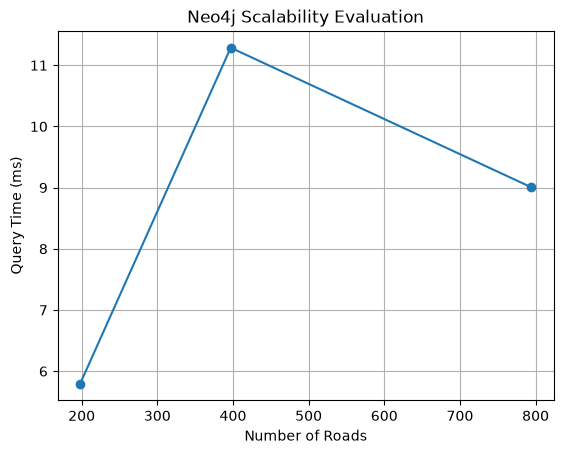

In [21]:
import matplotlib.pyplot as plt

plt.plot(
    scalability_df["Roads"],
    scalability_df["Query Time (ms)"],
    marker="o"
)

plt.xlabel("Number of Roads")
plt.ylabel("Query Time (ms)")
plt.title("Neo4j Scalability Evaluation")
plt.grid(True)

plt.savefig(
    project_folder / "presentation" / "screenshots" / "phase3_scalability.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [22]:
output = project_folder / "data" / "outputs" / "scalability_results.csv"

scalability_df.to_csv(output, index=False)

print("Scalability results saved!")

Scalability results saved!


In [1]:
import pandas as pd
from pathlib import Path

project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

folder = project_folder / "data" / "outputs"

completeness = pd.read_csv(folder / "graph_completeness.csv")
performance = pd.read_csv(folder / "query_performance.csv")
index = pd.read_csv(folder / "index_performance.csv")
scalability = pd.read_csv(folder / "scalability_results.csv")

print("GRAPH COMPLETENESS")
print(completeness.to_string(index=False))

print("\nQUERY PERFORMANCE")
print(performance.to_string(index=False))

print("\nINDEX PERFORMANCE")
print(index.to_string(index=False))

print("\nSCALABILITY")
print(scalability.to_string(index=False))

GRAPH COMPLETENESS
    Entity  Source Count  Neo4j Count  Completeness (%)
     Roads           794          794             100.0
 Junctions           276          276             100.0
 Incidents             3            3             100.0
Congestion            75           75             100.0

QUERY PERFORMANCE
               Query  Avg Time (ms)  Min Time (ms)  Max Time (ms)
           All Roads          5.794          5.510          6.137
       Blocked Roads          7.236          6.022         10.467
    High Speed Roads          5.426          5.090          5.932
 Simulated Incidents          4.832          4.522          5.228
     Congested Roads          5.278          4.946          5.690
Incident Connections          6.115          5.041          8.798

INDEX PERFORMANCE
          Method  Matched Roads  Avg Time (ms)
     Using Index            753          4.771
Using Label Scan            753          5.846

SCALABILITY
 Dataset (%)  Roads  Junctions  Connections  Lo